# Customer Segmentation: RFM + K-Means

Segmenting **5,000 customers (24,000+ orders)** of a D2C e-commerce brand by purchasing behaviour, so marketing can target each group differently.

**Workflow:** SQL feature extraction → log transform & scaling → choose k (elbow + silhouette) → K-Means → segment profiling → marketing actions.

> Dataset is synthetic. Build the database with `python src/generate_data.py`.

In [1]:
import sys, sqlite3, pandas as pd
sys.path.append('../src')
from IPython.display import Image, display
import segmentation as seg
pd.set_option('display.float_format', '{:,.2f}'.format)
con = sqlite3.connect('../data/ecommerce.db')

## 1. Explore the database with SQL

In [2]:
pd.read_sql_query('SELECT * FROM orders LIMIT 5', con)

,order_id,customer_id,order_date,category,items,gross_amount,discount_amount,net_amount,coupon_used,status
0,O500000,C00001,2025-11-02,Gift Sets,1,"1,233.88",0.00,"1,233.88",0,Delivered
1,O500001,C00001,2025-11-03,Men's Socks,1,"1,097.38",0.00,"1,097.38",0,Delivered
2,O500002,C00002,2024-03-28,Men's Socks,2,773.94,0.00,773.94,0,Cancelled
3,O500003,C00002,2024-08-02,Kids' Socks,2,768.34,0.00,768.34,0,Returned
4,O500004,C00002,2025-01-12,Gift Sets,2,836.81,167.36,669.45,1,Delivered


In [3]:
pd.read_sql_query('''
SELECT c.acquisition_channel,
       COUNT(DISTINCT c.customer_id) AS customers,
       ROUND(SUM(o.net_amount) / COUNT(DISTINCT c.customer_id), 0) AS revenue_per_customer
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id AND o.status = 'Delivered'
GROUP BY c.acquisition_channel
ORDER BY revenue_per_customer DESC''', con)

,acquisition_channel,customers,revenue_per_customer
0,Referral,668,"7,168.00"
1,Google Search,1102,"6,551.00"
2,Instagram Ads,1558,"6,335.00"
3,Marketplace,807,"6,154.00"
4,Organic,781,"6,137.00"


## 2. Extract customer-level features (RFM + behaviour) with SQL
See `sql/02_customer_features.sql`: recency, frequency, monetary value, average order value, coupon usage, return rate and tenure per customer.

In [4]:
features = seg.load_features()
print(features.shape)
features.head()

(4916, 13)


,customer_id,city_tier,age_group,acquisition_channel,recency_days,tenure_days,frequency,monetary,avg_order_value,coupon_rate,discount_share,categories_bought,return_rate
0,C00001,Tier 1,25-34,Referral,59,60,2,"2,331.26","1,165.63",0.00,0.00,2,0.00
1,C00002,Tier 3,18-24,Organic,354,702,1,669.45,669.45,1.00,0.20,1,0.33
2,C00003,Tier 2,25-34,Instagram Ads,593,593,1,530.65,530.65,0.00,0.00,1,0.00
3,C00004,Tier 1,18-24,Referral,88,653,4,"4,563.59","1,140.90",0.25,0.04,3,0.20
4,C00005,Tier 2,18-24,Instagram Ads,25,465,5,"6,184.22","1,236.84",0.00,0.00,3,0.00


In [5]:
features[seg.FEATURES].describe()

,recency_days,frequency,monetary,avg_order_value,coupon_rate
count,"4,916.00","4,916.00","4,916.00","4,916.00","4,916.00"
mean,178.41,4.63,"6,435.22","1,051.05",0.39
std,193.92,3.91,"9,527.07",546.71,0.37
min,2.00,1.00,330.70,330.70,0.00
25%,33.00,2.00,"1,338.53",662.01,0.00
50%,80.50,3.00,"2,313.54",964.88,0.32
75%,321.00,6.00,"6,949.81","1,189.51",0.67
max,724.00,20.00,"51,328.62","2,867.80",1.00


Monetary and frequency are heavily right-skewed, so they are **log-transformed** before scaling; otherwise a few big spenders would dominate the distance calculation.

## 3. Cluster, choose k and profile segments

In [6]:
df, summary, scores, sil = seg.run(k=5, verbose=False)
scores.round(3)

,k,inertia,silhouette
0,2,"14,062.75",0.38
1,3,"10,267.03",0.38
2,4,"7,843.84",0.39
3,5,"5,909.74",0.43
4,6,"4,891.17",0.45
5,7,"4,098.83",0.45
6,8,"3,579.52",0.46
7,9,"3,365.30",0.39


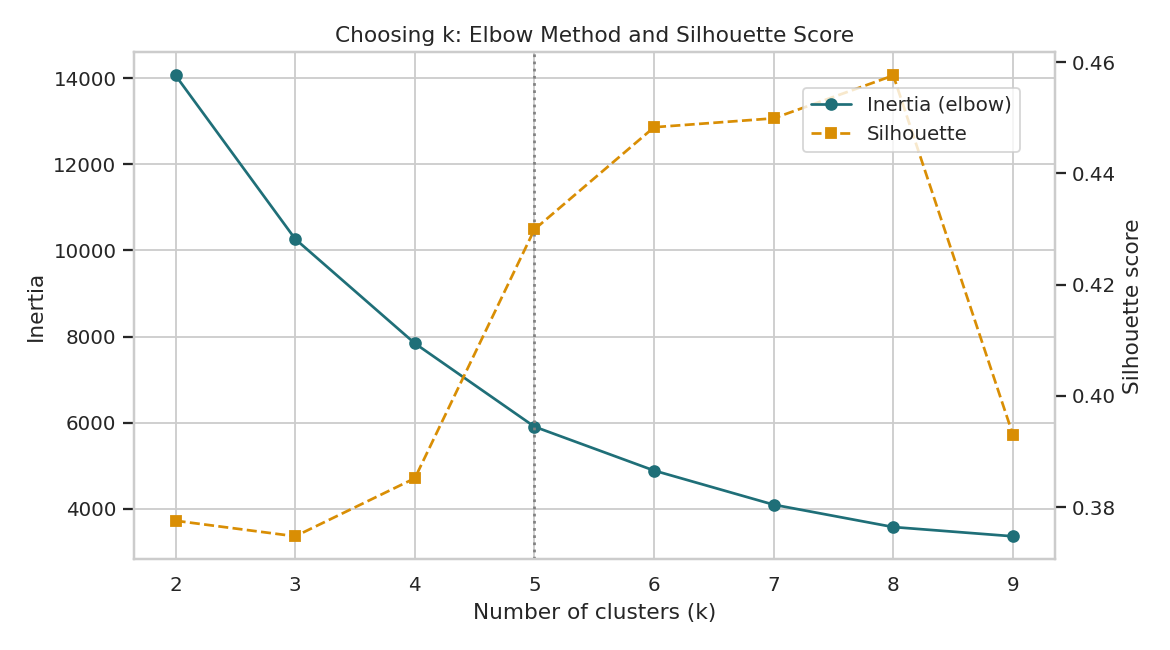

In [7]:
display(Image('../reports/figures/01_k_selection.png'))

The silhouette score jumps at **k = 5** (0.385 → 0.43) and gains flatten after that, while the elbow curve bends around 5. Five segments also stay actionable for a marketing team.

In [8]:
print(f'Silhouette score (k=5): {sil:.3f}')
summary

Silhouette score (k=5): 0.428


,customers,revenue,customer_share,revenue_share,recency_days,frequency,monetary,avg_order_value,coupon_rate,tenure_days
segment,,,,,,,,,,
Champions,586,"17,653,406.73",0.12,0.56,27.22,12.87,"30,125.27","2,341.92",0.15,581.07
Loyal Regulars,1280,"8,945,639.88",0.26,0.28,70.45,6.10,"6,988.78","1,148.00",0.25,574.72
Discount Seekers,1285,"2,360,234.63",0.26,0.07,197.04,3.35,"1,836.76",596.00,0.90,509.91
At-Risk / Lapsed,1108,"1,668,553.67",0.23,0.05,452.08,1.90,"1,505.91",796.74,0.17,579.94
New Customers,657,"1,007,687.96",0.13,0.03,25.64,1.51,"1,533.77","1,029.67",0.24,64.19


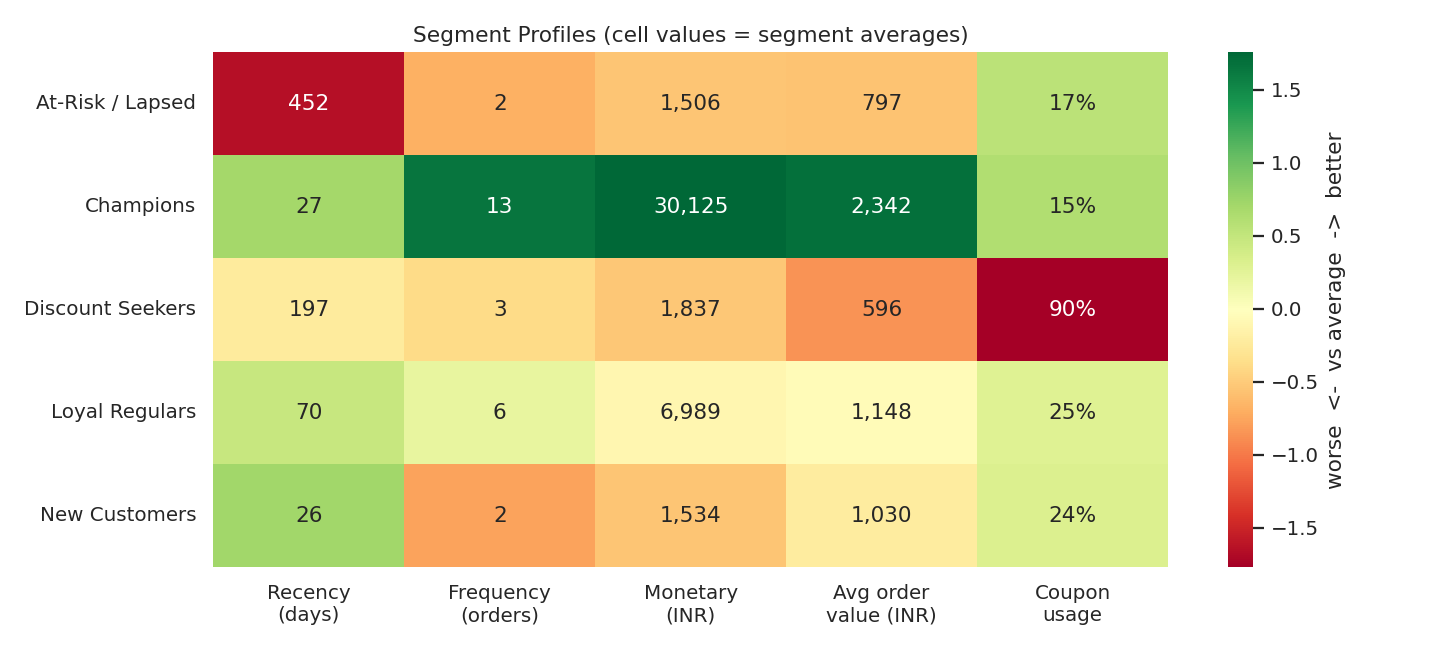

In [9]:
display(Image('../reports/figures/03_segment_profiles.png'))

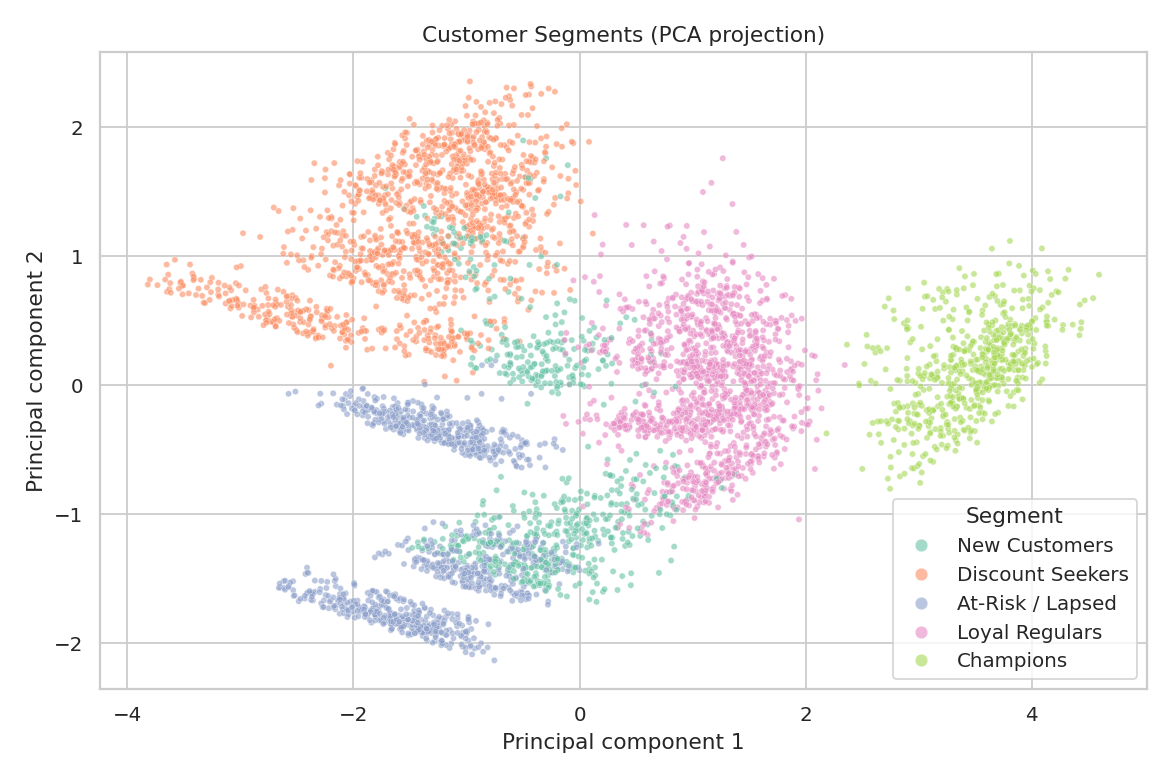

In [10]:
display(Image('../reports/figures/02_segments_pca.png'))

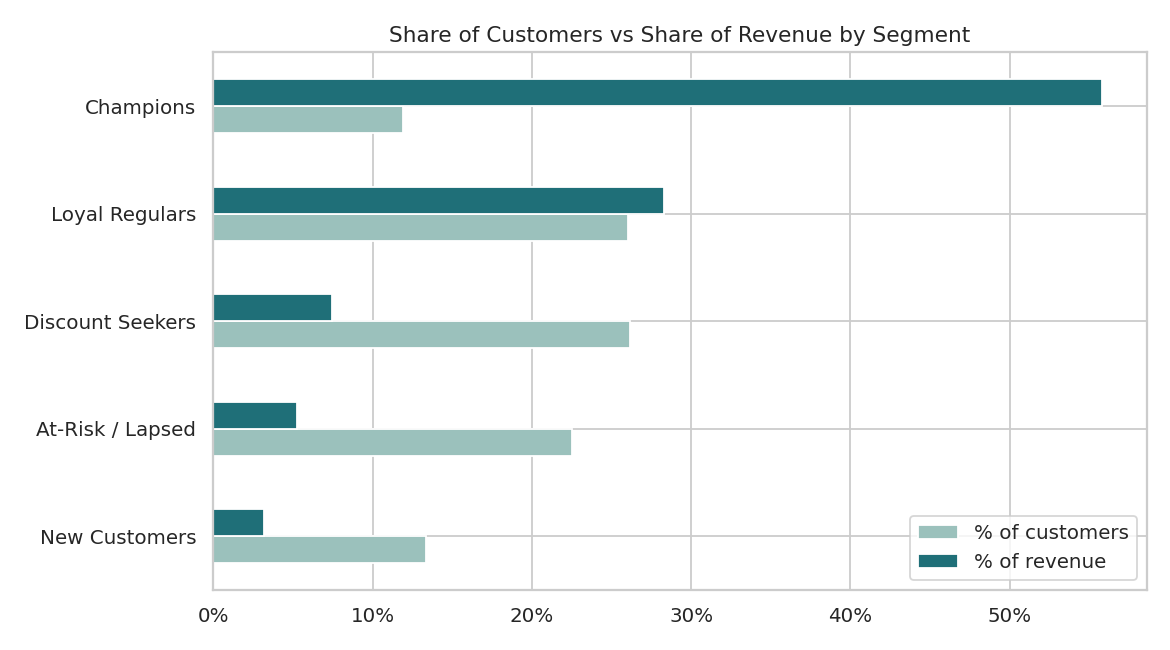

In [11]:
display(Image('../reports/figures/04_customers_vs_revenue.png'))

## 4. Segment-wise marketing strategy

| Segment | Who they are | Action |
|---|---|---|
| **Champions** (~12% of customers, ~56% of revenue) | Bought recently, often, at high order values | VIP early access, loyalty rewards, referral programme; avoid unnecessary discounts |
| **Loyal Regulars** (~26%, ~28%) | Steady repeat buyers | Cross-sell gift sets, subscription / bundle offers to move them up to Champions |
| **Discount Seekers** (~26%, ~8%) | Buy almost only with coupons, low basket | Margin-safe offers: minimum-order thresholds, bundles instead of flat discounts |
| **New Customers** (~13%, ~3%) | Joined in the last ~2 months | Onboarding email/WhatsApp flow, second-purchase incentive within 30 days |
| **At-Risk / Lapsed** (~22%, ~5%) | No purchase for over a year on average | Win-back campaign with a time-limited offer; suppress from paid ads if no response |

In [12]:
con.close()